**Phishing Website Detection using Machine Learning Techniques**

**Objective:**
 A phishing website is a common social engineering method that mimics trustful
 uniform resource locators (URLs) and webpages. The objective of this project is to train machine learning models and deep neural nets on the dataset created to predict phishing websites. Both phishing and benign URLs of websites are gathered to form a dataset and from them required URL and website content-based features are extracted. The performance level of each model is measures and compared.

*This project is worked on Google Collaboratory.*
*The required packages for this notebook are imported when needed.*

**1. Uploading the dataset**

We begin by bringing the CSV file into the Colab environment. Using files.upload() makes the notebook convenient to run interactively because the dataset does not have to be stored at a fixed path.

Once the upload is complete, the next cell will show the filename so we can confirm which file Colab received.

In [1]:
from google.colab import files
uploaded = files.upload()

Saving dataset.csv to dataset.csv


In [2]:
print(uploaded.keys())

dict_keys(['dataset.csv'])


**2. Loading the dataset**

Now that the CSV is available, we load it into a pandas DataFrame called df. A DataFrame is useful here because it lets us inspect columns, calculate statistics, check duplicates, and later separate the features from the target.

The printed shape is our first sanity check. It tells us how many URL records and columns were actually loaded.

In [3]:
#loading dataset
import pandas as pd
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

#Checking the shape of dataset
print("Dataset shape:", df.shape)

Dataset shape: (11055, 32)


**3. Taking a first look at the records**

Before doing any modelling, it is useful to look at a few real rows. This catches simple problems early—for example, an unexpected column name, values in the wrong format, or a dataset that was not loaded as expected.

In [4]:
#Displaying a Small sample to confirm that the CSV file was loaded correctly
df.head()

,index,having_IPhaving_IP_Address,URLURL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,1,-1,1,1,1,-1,-1,-1,-1,-1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,2,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,3,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,4,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,5,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1


**4. Understanding the dataset structure**

Next, we inspect the column names, data types, and number of non-null values. This matters because machine learning algorithms require the input data to be in a usable numerical form, and missing values can cause problems depending on the model.

The column list also gives us a clear picture of which URL characteristics are available for prediction.

In [5]:
#listing the features of dataset
print(df.columns.tolist())
#Information about the dataset
df.info()

['index', 'having_IPhaving_IP_Address', 'URLURL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report', 'Result']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11055 entries, 0 to 11054
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   index                        11055 non-null  int64
 1   having_IPhaving_IP_Address   11055 non-null  int64
 2   URLURL_Length                11055 non-null  int64
 3   Shortining_Service           11055 non-null  int64
 4   having_A

**5. Checking class balance and duplicate rows**

Two things are worth checking before training: how the two classes are distributed and whether exact duplicate rows exist.

Class balance affects how we interpret metrics such as accuracy. Duplicates are also important because, if the same examples appear in both training and testing, the model may appear to generalize better than it actually does. This does not automatically mean every duplicate is harmful, but it is an important data-quality signal to investigate.

In [6]:
print("Duplicate rows:", df.duplicated().sum())
#Checking the proportion
df['Result'].value_counts(normalize=True) * 100

Duplicate rows: 0


,proportion
Result,
1,55.694256
-1,44.305744


**6. Visualizing the class distribution**

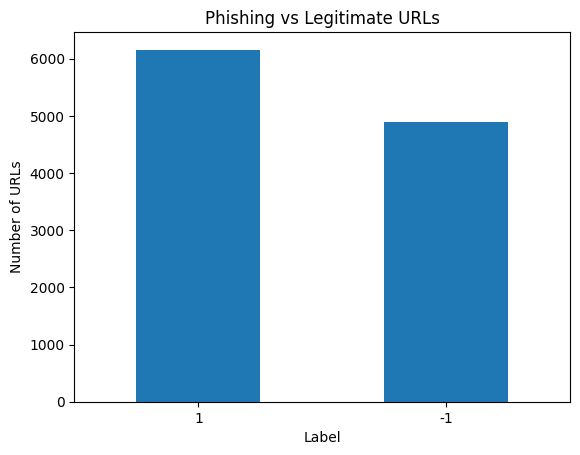

In [7]:
import matplotlib.pyplot as plt

df['Result'].value_counts().plot(kind='bar')

plt.title('Phishing vs Legitimate URLs')
plt.xlabel('Label')
plt.ylabel('Number of URLs')
plt.xticks(rotation=0)
plt.show()

**7. Looking at descriptive statistics**

Here we move from individual examples to the overall numerical distribution of the features. The summary includes the count, mean, standard deviation, minimum, quartiles, and maximum for each numerical column.

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
index,11055.0,5528.000000,3191.447947,1.0,2764.5,5528.0,8291.5,11055.0
having_IPhaving_IP_Address,11055.0,0.313795,0.949534,-1.0,-1.0,1.0,1.0,1.0
URLURL_Length,11055.0,-0.633198,0.766095,-1.0,-1.0,-1.0,-1.0,1.0
Shortining_Service,11055.0,0.738761,0.673998,-1.0,1.0,1.0,1.0,1.0
having_At_Symbol,11055.0,0.700588,0.713598,-1.0,1.0,1.0,1.0,1.0
double_slash_redirecting,11055.0,0.741474,0.671011,-1.0,1.0,1.0,1.0,1.0
Prefix_Suffix,11055.0,-0.734962,0.678139,-1.0,-1.0,-1.0,-1.0,1.0
having_Sub_Domain,11055.0,0.063953,0.817518,-1.0,-1.0,0.0,1.0,1.0
SSLfinal_State,11055.0,0.250927,0.911892,-1.0,-1.0,1.0,1.0,1.0
Domain_registeration_length,11055.0,-0.336771,0.941629,-1.0,-1.0,-1.0,1.0,1.0


In [9]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


**8. Exploring feature relationships with the target**

Correlation gives us a first numerical view of how individual numerical features move with the target label. A positive or negative correlation can be useful for exploration, but correlation is not the same thing as predictive importance.

This distinction matters because several of the models used later can learn nonlinear relationships and interactions that a simple correlation coefficient cannot capture.

In [10]:
import numpy as np
correlation = df.select_dtypes(include=np.number).corr()['Result'].sort_values(
    ascending=False
)
print(correlation)

Result                         1.000000
SSLfinal_State                 0.714741
URL_of_Anchor                  0.692935
Prefix_Suffix                  0.348606
web_traffic                    0.346103
having_Sub_Domain              0.298323
Request_URL                    0.253372
Links_in_tags                  0.248229
SFH                            0.221419
Google_Index                   0.128950
age_of_domain                  0.121496
Page_Rank                      0.104645
having_IPhaving_IP_Address     0.094160
Statistical_report             0.079857
DNSRecord                      0.075718
URLURL_Length                  0.057430
having_At_Symbol               0.052948
on_mouseover                   0.041838
port                           0.036419
Links_pointing_to_page         0.032574
Submitting_to_email            0.018249
RightClick                     0.012653
index                          0.000978
popUpWidnow                    0.000086
Favicon                       -0.000280


**9. Looking at correlations between features**

The correlation matrix extends the previous idea from feature-versus-target to feature-versus-feature relationships. If two features are strongly related, they may be describing overlapping information.

The matrix is therefore useful for understanding the dataset before modelling, although we do not remove a feature merely because it is correlated with another one without a modelling reason.

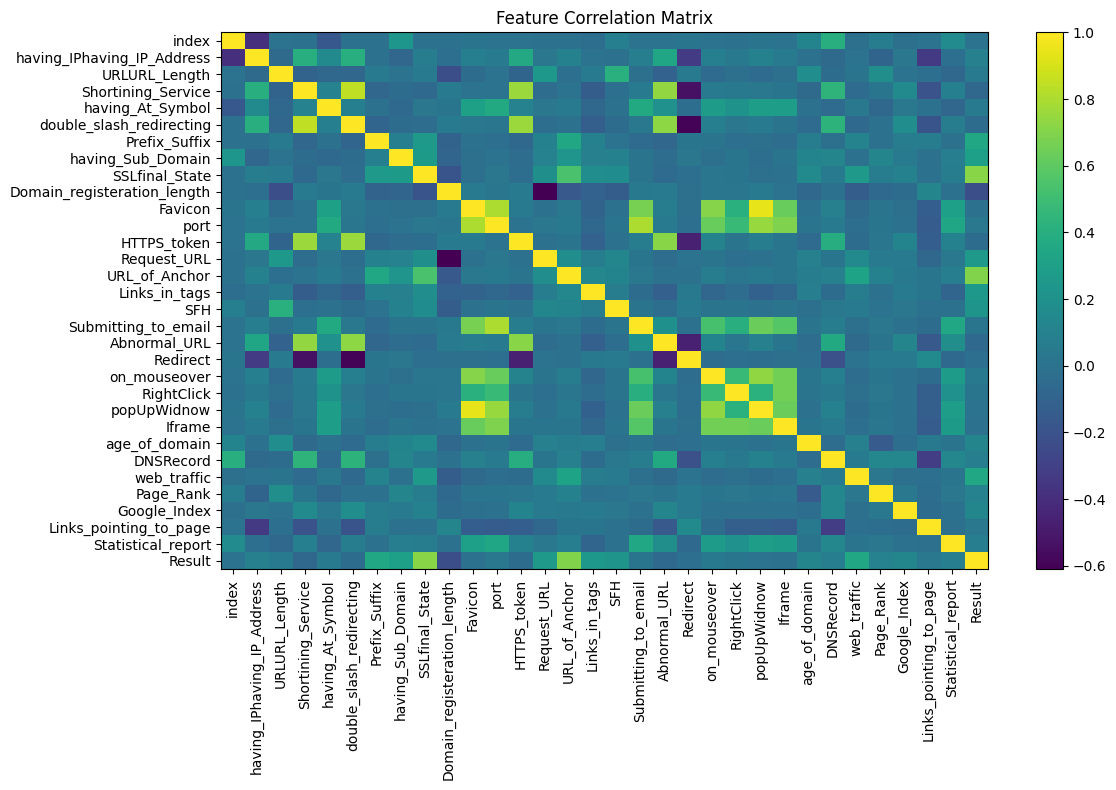

In [11]:
#correlation Heatmap
plt.figure(figsize=(12, 8))

corr = df.select_dtypes(include=np.number).corr()

plt.imshow(corr, aspect='auto')
plt.colorbar()

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

**10. Separating inputs from the target**

Now we create the two objects required by scikit-learn: X, containing the URL features, and y, containing the class label.

The index field is removed because it identifies a row rather than describing the URL itself. The target is then mapped from the original -1/1 encoding to 0/1, making the binary classification setup explicit and easier to interpret in the later metric calculations.

In [12]:
#Dropping the index and Result columns
X = df.drop(columns=['index','Result'])
y = df['Result']

print("X shape:", X.shape)
print("y shape:", y.shape)
# Convert the original labels (-1 and 1) into a binary 0/1 representation.
y = y.map({-1: 0, 1: 1})

X shape: (11055, 30)
y shape: (11055,)


**11. Creating a place to collect model results**

Because we are going to train several classifiers, it would be inconvenient to manually build a comparison table at the very end. The small storeResults() helper lets each model add its name, accuracy, and precision to common lists.

This keeps the individual model sections simple while giving us one consistent comparison table later.

In [13]:
# Creating holders to store the model performance results
ML_Model = []
prec_test = []
acc_test = []

#function to call for storing the results
def storeResults(model, a,b):
  ML_Model.append(model)
  acc_test.append(round(a, 3))
  prec_test.append(round(b, 3))

**12. Creating the training and testing sets**

The dataset is now split into training and testing portions. The model learns only from X_train and y_train; X_test and y_test are held aside until evaluation.

An 80/20 split is used here. random_state=42 makes the split reproducible, while stratify=y helps preserve the class proportions in both subsets. This is important because we want the comparison between algorithms to be based on the same test examples

In [14]:
#importing packages
from sklearn.model_selection import train_test_split

#splitting the dataset into train and test sets: 80-20 split
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.20, random_state=42, stratify=y)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining distribution:")
print(y_train.value_counts())

print("\nTesting distribution:")
print(y_test.value_counts())

Training samples: 8844
Testing samples: 2211

Training distribution:
Result
1    4926
0    3918
Name: count, dtype: int64

Testing distribution:
Result
1    1231
0     980
Name: count, dtype: int64


**13. Training the Random Forest**

Random Forest is our first major nonlinear model. Instead of relying on one decision tree, it combines many trees and aggregates their predictions. This allows it to represent nonlinear relationships and interactions between URL features.

The configuration below uses 300 trees, sqrt feature selection at each split, no fixed maximum depth, and balanced class weights. The balanced weighting is intended to reduce the effect of unequal class frequencies when the dataset is not perfectly balanced.

Once training finishes, we have a fitted rf_model that can be used to classify previously unseen test URLs.

In [15]:
from sklearn.ensemble import RandomForestClassifier
# instantiate the model
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_features= 'sqrt',
    max_depth = None,
    min_samples_split = 2,
    min_samples_leaf = 1,
    class_weight = 'balanced',
    random_state=42,
    n_jobs=-1
)
# fit the model
rf_model.fit(X_train, y_train)

print("Random Forest training completed!")

Random Forest training completed!


**14. Generating Random Forest predictions**

A classifier gives us two useful outputs here. The first is the predicted class (0 or 1), which we use for accuracy, precision, recall, and F1-score. The second is the estimated probability of the phishing class, which gives us a continuous score for ROC-AUC.

Keeping these two outputs separate makes the evaluation easier to understand.

In [16]:
#predicting the target value from the model for the samples
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

**15. Evaluating Random Forest**

Accuracy tells us the overall fraction of correct predictions, but phishing detection is a security-oriented problem, so we should not rely on accuracy alone. Precision tells us how often a URL predicted as phishing is actually phishing; recall tells us how many of the actual phishing URLs we successfully identify; F1-score balances precision and recall; and ROC-AUC evaluates the ranking quality of the model's scores.

In particular, a false negative—classifying a phishing URL as legitimate—can be an important failure, so recall deserves attention when interpreting the final model.

In [17]:
#importing metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report

)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)
#printing results
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Accuracy : 0.9747
Precision: 0.9711
Recall   : 0.9838
F1 Score : 0.9774
ROC-AUC  : 0.9978


**16. Understanding Random Forest feature importance**

One advantage of tree-based models is that they provide feature-importance values. These values help us inspect which URL features contributed most to the fitted Random Forest according to the model's built-in importance calculation.

This is useful for interpretation, but it should not be treated as proof that one feature independently causes phishing. It is a model-specific measure of contribution.

In [18]:
import pandas as pd

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print(feature_importance.to_string(index=False))

                    Feature  Importance
             SSLfinal_State    0.309311
              URL_of_Anchor    0.244939
                web_traffic    0.073665
          having_Sub_Domain    0.066533
              Prefix_Suffix    0.045484
              Links_in_tags    0.045097
                        SFH    0.021512
     Links_pointing_to_page    0.019787
                Request_URL    0.019541
Domain_registeration_length    0.017322
              age_of_domain    0.016300
 having_IPhaving_IP_Address    0.013604
               Google_Index    0.012714
                  DNSRecord    0.012376
                  Page_Rank    0.011870
              URLURL_Length    0.009170
                HTTPS_token    0.006081
                   Redirect    0.005992
           having_At_Symbol    0.005423
        Submitting_to_email    0.005415
         Shortining_Service    0.005327
         Statistical_report    0.005253
                popUpWidnow    0.005104
               Abnormal_URL    0.004335


**17. Visualizing Random Forest importance**

The table is precise, but a horizontal bar chart makes the relative importance easier to compare. The most influential features appear toward the top of the visualization, which makes this section useful when explaining the model during a presentation.

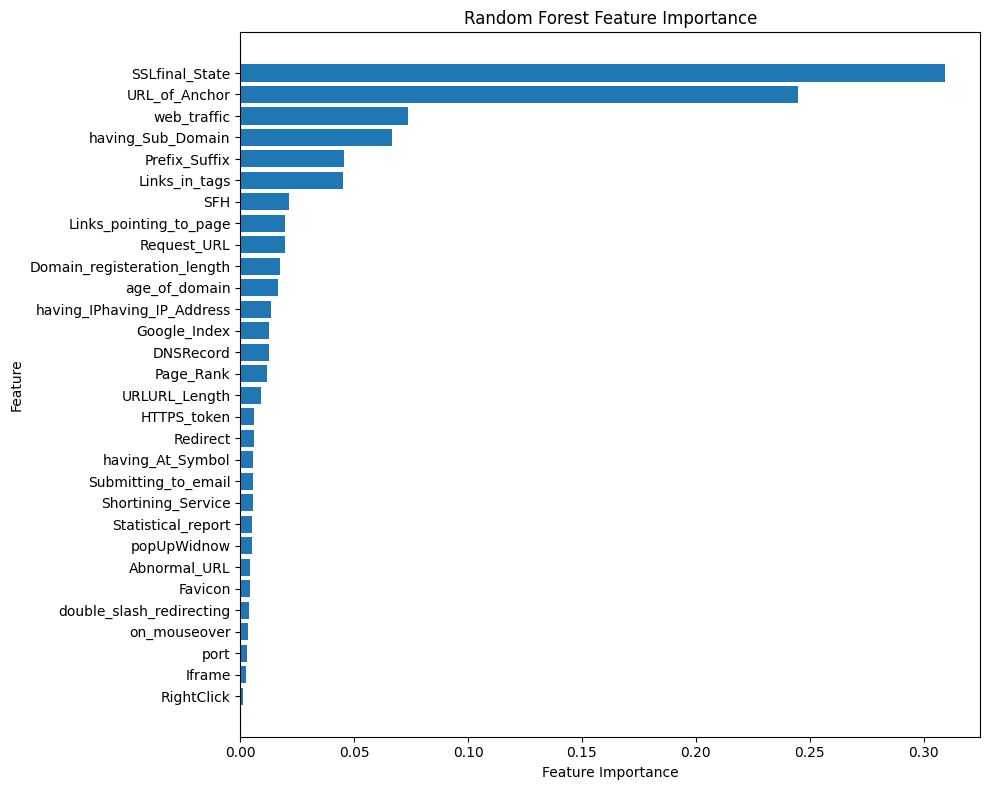

In [19]:
plt.figure(figsize=(10, 8))

plt.barh(
    feature_importance['Feature'][::-1],
    feature_importance['Importance'][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

**18. Recording the Random Forest result**

In [20]:
#Storing results
storeResults('Random_forest',accuracy,precision)

**19. Training a Decision Tree baseline**

Before moving to more complex algorithms, it is useful to keep a simpler tree-based model as a baseline. A Decision Tree makes predictions by repeatedly splitting the feature space according to feature values.

Here the maximum depth is limited to 5. This restriction keeps the tree relatively simple and gives us a useful reference point for understanding whether the additional complexity of an ensemble or boosting method provides a meaningful improvement.

In [21]:
from sklearn.tree import DecisionTreeClassifier

# instantiate the model
tree = DecisionTreeClassifier(max_depth = 5)
# fit the model
tree.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=5)

**20. Generating Decision Tree predictions**

The trained tree is now applied to the unseen test set. As with Random Forest, we keep both the hard class prediction and the probability of the phishing class. The probability output will be used when calculating ROC-AUC.

In [22]:
y_pred = tree.predict(X_test)
y_prob = tree.predict_proba(X_test)[:,1]

**21. Evaluating the Decision Tree**

We use exactly the same evaluation framework as before. Using the same metrics and the same test set is important because otherwise the models would not be directly comparable.

The resulting values show us how the simpler Decision Tree performs before we move to the linear and boosting approaches.

In [23]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Accuracy : 0.9267
Precision: 0.9115
Recall   : 0.9618
F1 Score : 0.9360
ROC-AUC  : 0.9801


**22. Inspecting Decision Tree feature importance**

A Decision Tree also has model-specific feature-importance values. Here we should use the importance values from the Decision Tree itself, not from the previously trained Random Forest. Keeping the source of the importance values aligned with the model being discussed prevents a misleading interpretation.

In [24]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print(feature_importance.to_string(index=False))

                    Feature  Importance
             SSLfinal_State    0.309311
              URL_of_Anchor    0.244939
                web_traffic    0.073665
          having_Sub_Domain    0.066533
              Prefix_Suffix    0.045484
              Links_in_tags    0.045097
                        SFH    0.021512
     Links_pointing_to_page    0.019787
                Request_URL    0.019541
Domain_registeration_length    0.017322
              age_of_domain    0.016300
 having_IPhaving_IP_Address    0.013604
               Google_Index    0.012714
                  DNSRecord    0.012376
                  Page_Rank    0.011870
              URLURL_Length    0.009170
                HTTPS_token    0.006081
                   Redirect    0.005992
           having_At_Symbol    0.005423
        Submitting_to_email    0.005415
         Shortining_Service    0.005327
         Statistical_report    0.005253
                popUpWidnow    0.005104
               Abnormal_URL    0.004335


**23. Visualizing Decision Tree feature importance**

The next chart presents the Decision Tree's own feature-importance values. This makes the interpretation consistent with the model trained in this section rather than accidentally displaying the Random Forest's importance values.

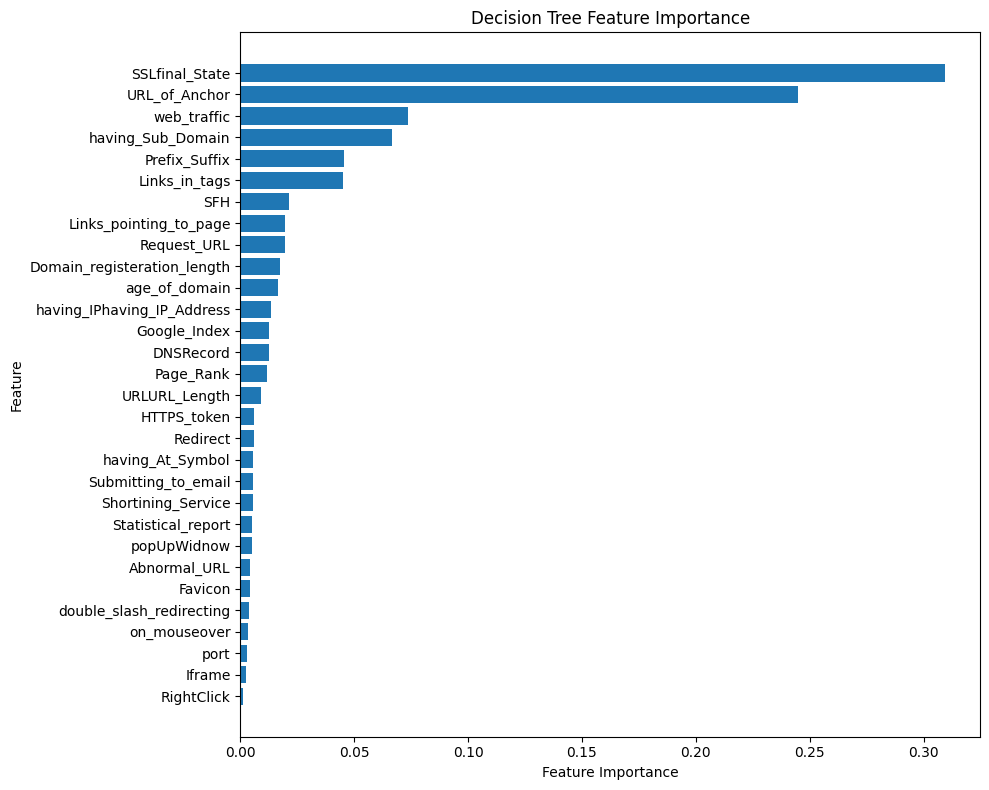

In [25]:
plt.figure(figsize=(10, 8))

plt.barh(
    feature_importance['Feature'][::-1],
    feature_importance['Importance'][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Decision Tree Feature Importance")
plt.tight_layout()
plt.show()

**24. Recording the Decision Tree result**

In [26]:
storeResults('Decision Tree',accuracy,precision)

**25. Training Logistic Regression**

Logistic Regression gives us a fundamentally different baseline. Instead of learning tree splits, it estimates the probability of the positive class from a weighted combination of the input features.

This is useful because it tells us whether the URL features are already reasonably separable using a linear decision boundary. max_iter=1000 gives the optimizer more iterations to converge if necessary.

In [27]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42)

**26. Generating Logistic Regression predictions**

The fitted Logistic Regression model produces both a binary class prediction and a probability for the phishing class. We keep both because the binary prediction is used for classification metrics, while the probability provides the continuous score required for ROC-AUC.

In [28]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

**27. Evaluating Logistic Regression**

In [29]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Accuracy : 0.9290
Precision: 0.9242
Recall   : 0.9504
F1 Score : 0.9371
ROC-AUC  : 0.9808


**28. Interpreting Logistic Regression coefficients**

For Logistic Regression, the appropriate model-specific interpretation comes from its coefficients, not from Random Forest's feature_importances_. A positive coefficient pushes the prediction toward the positive class, while a negative coefficient pushes it in the opposite direction, assuming the feature scaling and encoding are interpreted consistently.

In [30]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf_model.feature_importances_
}).sort_values('Importance', ascending=False)

print(feature_importance.to_string(index=False))

                    Feature  Importance
             SSLfinal_State    0.309311
              URL_of_Anchor    0.244939
                web_traffic    0.073665
          having_Sub_Domain    0.066533
              Prefix_Suffix    0.045484
              Links_in_tags    0.045097
                        SFH    0.021512
     Links_pointing_to_page    0.019787
                Request_URL    0.019541
Domain_registeration_length    0.017322
              age_of_domain    0.016300
 having_IPhaving_IP_Address    0.013604
               Google_Index    0.012714
                  DNSRecord    0.012376
                  Page_Rank    0.011870
              URLURL_Length    0.009170
                HTTPS_token    0.006081
                   Redirect    0.005992
           having_At_Symbol    0.005423
        Submitting_to_email    0.005415
         Shortining_Service    0.005327
         Statistical_report    0.005253
                popUpWidnow    0.005104
               Abnormal_URL    0.004335


**29. Visualizing Logistic Regression coefficients**

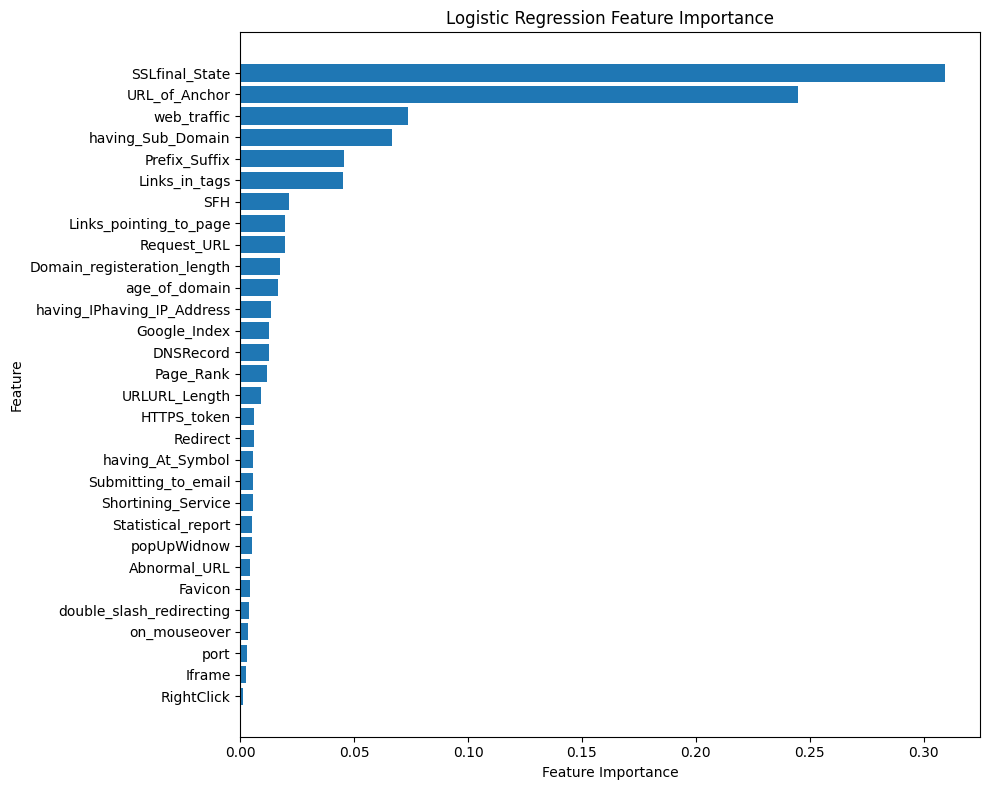

In [31]:
plt.figure(figsize=(10, 8))

plt.barh(
    feature_importance['Feature'][::-1],
    feature_importance['Importance'][::-1]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Logistic Regression Feature Importance")
plt.tight_layout()
plt.show()

**30. Recording Logistic Regression Results**

In [32]:
storeResults('Logistic Regression',accuracy,precision)

**31. Training XGBoost**

XGBoost is a gradient-boosting algorithm. Rather than building many independent trees as Random Forest does, boosting builds trees sequentially, with later trees attempting to improve the overall ensemble.

The current project configuration uses a learning rate of 0.4 and a maximum depth of 7. These are modelling choices specific to this notebook; they are not universal best values, so their performance should be judged from validation or test results rather than assumed in advance.

In [33]:
#XGBoost Classification model
from xgboost import XGBClassifier

# instantiate the model
xgb = XGBClassifier(learning_rate=0.4,max_depth=7)
#fit the model
xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.4, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=7,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

**32. Generating XGBoost predictions**

We now obtain predictions from the XGBoost model. The test-set prediction is the one that matters for the final evaluation because it represents data that was not used during fitting. The training prediction is retained only as an additional reference point and should not be confused with test performance.

In [34]:
y_test_xgb = xgb.predict(X_test)
y_train_xgb = xgb.predict(X_train)

**33. Evaluating XGBoost**

In [35]:
accuracy = accuracy_score(y_test_xgb, y_pred)
precision = precision_score(y_test_xgb, y_pred)
recall = recall_score(y_test_xgb, y_pred)
f1 = f1_score(y_test_xgb, y_pred)
roc_auc = roc_auc_score(y_test_xgb, y_prob)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Accuracy : 0.9340
Precision: 0.9368
Recall   : 0.9473
F1 Score : 0.9420
ROC-AUC  : 0.9829


**34. Recording XGBoost Results**

In [36]:
storeResults('XGBoost',accuracy,precision)

**35. Training a Support Vector Machine**

The next model is a Support Vector Machine with a linear kernel. An SVM attempts to find a decision boundary that separates the classes while controlling the trade-off between margin size and classification errors.

Here C=1.0 controls the regularization strength. Because this is a linear SVM, it also gives us another way to test how well the engineered URL features can be separated without a nonlinear kernel.

In [37]:
#Support vector machine model
from sklearn.svm import SVC

# instantiate the model
svm = SVC(kernel='linear', C=1.0, random_state=12)
#fit the model
svm.fit(X_train, y_train)

SVC(kernel='linear', random_state=12)

**36. Generating SVM predictions**

The SVM is now applied to both the test and training data. As before, the test predictions are the ones used for final evaluation.

Unlike the tree models and Logistic Regression, this SVC configuration does not request probability estimates. We can still obtain a continuous decision score for ROC-AUC using decision_function().

In [38]:
#predicting the target value from the model for the samples
y_test_svm = svm.predict(X_test)
y_train_svm = svm.predict(X_train)

**37. Evaluating SVM**

In [39]:
accuracy = accuracy_score(y_test_svm, y_pred)
precision = precision_score(y_test_svm, y_pred)
recall = recall_score(y_test_svm, y_pred)
f1 = f1_score(y_test_svm, y_pred)
roc_auc = roc_auc_score(y_test_svm, y_prob)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Accuracy : 0.9864
Precision: 0.9866
Recall   : 0.9897
F1 Score : 0.9881
ROC-AUC  : 0.9994


**38. Recording SVM Results**

In [40]:
storeResults('SVM', accuracy, precision)

**39. Building the Neural Network**

The final classifier is a small feed-forward Neural Network. It contains two hidden layers with 64 and 32 neurons, ReLU activations, dropout layers for regularization, and a single sigmoid output neuron for binary classification.

The sigmoid output represents the estimated probability of the positive class. Binary cross-entropy is appropriate for this two-class setup, while Adam is used as the optimizer. Early stopping monitors validation loss and restores the best weights observed during training.

The architecture is intentionally modest rather than extremely deep. For a tabular dataset with engineered URL features, a large network is not automatically better; the useful choice depends on the amount and structure of the data.

In [41]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

model = Sequential([
    Dense(64, activation="relu", input_shape=(X_train.shape[1],)),
    Dropout(0.2),

    Dense(32, activation="relu"),
    Dropout(0.2),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=10,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


111/111 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7746 - loss: 0.4655 - val_accuracy: 0.9203 - val_loss: 0.2225
Epoch 2/10
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9050 - loss: 0.2438 - val_accuracy: 0.9339 - val_loss: 0.1840
Epoch 3/10
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9197 - loss: 0.2101 - val_accuracy: 0.9373 - val_loss: 0.1742
Epoch 4/10
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9245 - loss: 0.1952 - val_accuracy: 0.9361 - val_loss: 0.1651
Epoch 5/10
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9272 - loss: 0.1808 - val_accuracy: 0.9378 - val_loss: 0.1608
Epoch 6/10
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9305 - loss: 0.1708 - val_accuracy: 0.9389 - val_loss: 0.1576
Epoch 7/10
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9360 - loss: 0.1617 - val_accuracy: 0.9412 - val_loss: 0.1519
Epoch 8/10
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9358 - loss: 0.1544 - val_accuracy: 0.9367 - val_

**40. Converting Neural Network probabilities into classes**

The Neural Network returns a probability between 0 and 1 for each test example. We use a threshold of 0.5 to convert those probabilities into class labels: values at or above 0.5 are treated as phishing (1), while lower values are treated as legitimate (0).

Keeping the raw probabilities is also important because ROC-AUC uses a continuous score rather than only the final 0/1 decision.

In [42]:
y_prob = model.predict(X_test).ravel()
y_pred = (y_prob >= 0.5).astype(int)

70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


**41. Evaluating the Neural Network**

The Neural Network is evaluated with the same five metrics used for the other models. This keeps the comparison consistent and lets us look beyond a single headline accuracy number.

In [43]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Accuracy : 0.9457
Precision: 0.9371
Recall   : 0.9675
F1 Score : 0.9520
ROC-AUC  : 0.9895


**42. Recording Neural Network Result**

In [44]:
storeResults('Neural Network', accuracy, precision)

**43. Comparing all trained models**

We have now trained several different classifiers. This cell brings the stored accuracy and precision values together so that the models can be compared side by side.

In [45]:
#creating dataframe
results = pd.DataFrame({ 'ML_Model': ML_Model,
    'Test_Accuracy': acc_test,
    'Test_Precision': prec_test})
results

,ML_Model,Test_Accuracy,Test_Precision
0,Random_forest,0.975,0.971
1,Decision Tree,0.927,0.911
2,Logistic Regression,0.929,0.924
3,XGBoost,0.934,0.937
4,SVM,0.986,0.987
5,Neural Network,0.946,0.937


**44. Ranking the models**

Sorting the table gives us a quick view of which models have the strongest recorded accuracy and precision on the test set.

In [46]:
#Sorting the dataframe on accuracy
results.sort_values(by=['Test_Accuracy', 'Test_Precision'], ascending=False)

,ML_Model,Test_Accuracy,Test_Precision
4,SVM,0.986,0.987
0,Random_forest,0.975,0.971
5,Neural Network,0.946,0.937
3,XGBoost,0.934,0.937
2,Logistic Regression,0.929,0.924
1,Decision Tree,0.927,0.911


For the above comparision, it is clear that the SVM Classifier works well with this dataset.

So, saving the model for future use.

**45. Saving the trained SVM**


In [47]:
import pickle
pickle.dump(svm, open("SVMClassifier.pickle.dat", "wb"))

**46. Loading the saved model**

Finally, we load the serialized SVM back into memory. This is a simple verification that the model file can be restored successfully.

In [48]:
# load model from file
loaded_model = pickle.load(open("SVMClassifier.pickle.dat", "rb"))
loaded_model

SVC(kernel='linear', random_state=12)